In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Lokasi proyek
BASE = "/content/drive/MyDrive/simuteh-1004"
DATA = os.path.join(BASE, "data", "sintetis")
CITRA = os.path.join(DATA, "citra")
BERSIH = os.path.join(DATA, "bersih")
MASK_DAUN = os.path.join(DATA, "mask_daun")
MASK_BERCAK = os.path.join(DATA, "mask_bercak")
HASIL = os.path.join(BASE, "hasil")
SRC = os.path.join(BASE, "src")

os.makedirs(HASIL, exist_ok=True)

# Memeriksa folder dan dataset
print("Folder proyek ditemukan:", os.path.exists(BASE))
print("Folder citra ditemukan:", os.path.exists(CITRA))
print("Folder src ditemukan:", os.path.exists(SRC))
print("Isi folder src:", os.listdir(SRC))
print("Jumlah citra:", len(os.listdir(CITRA)))

Mounted at /content/drive
Folder proyek ditemukan: True
Folder citra ditemukan: True
Folder src ditemukan: True
Isi folder src: ['buat_dataset_sintetis.py', 'utils_cv.py', '__pycache__']
Jumlah citra: 60


In [ ]:
import importlib.util

file_utils = os.path.join(SRC, "utils_cv.py")

spec = importlib.util.spec_from_file_location("utils_cv", file_utils)
utils_cv = importlib.util.module_from_spec(spec)
spec.loader.exec_module(utils_cv)

baca = utils_cv.baca
tampil = utils_cv.tampil
kontras_bercak = utils_cv.kontras_bercak
statistik = utils_cv.statistik

print("utils_cv.py berhasil dimuat!")

utils_cv.py berhasil dimuat!


Nama file: teh_041.png
Ukuran citra: (480, 640, 3)
Tipe data: uint8
Nilai piksel minimum: 0
Nilai piksel maksimum: 255


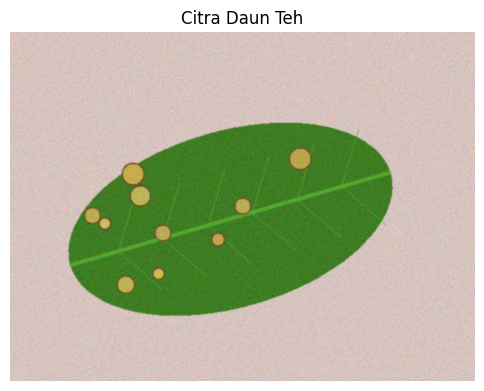

In [ ]:
nama_file = "teh_041.png"
path_citra = os.path.join(CITRA, nama_file)

img = baca(path_citra)

print("Nama file:", nama_file)
print("Ukuran citra:", img.shape)
print("Tipe data:", img.dtype)
print("Nilai piksel minimum:", img.min())
print("Nilai piksel maksimum:", img.max())

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Citra Daun Teh")
plt.axis("off")
plt.show()

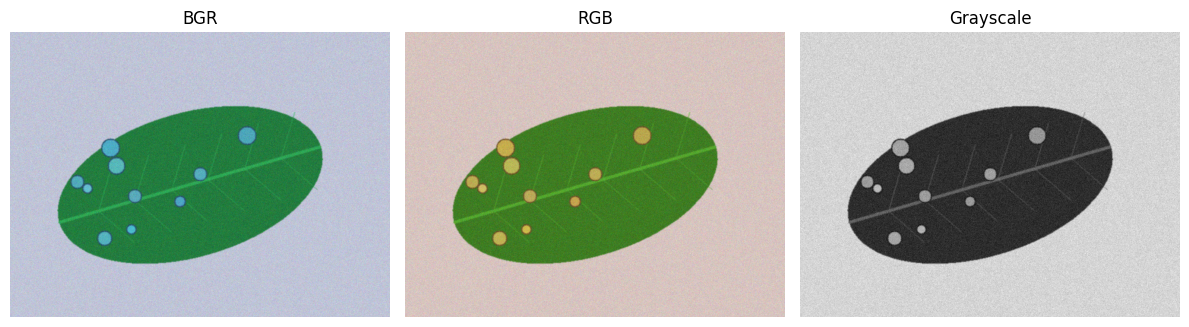

In [ ]:
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("BGR")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(rgb)
plt.title("RGB")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.tight_layout()
plt.show()

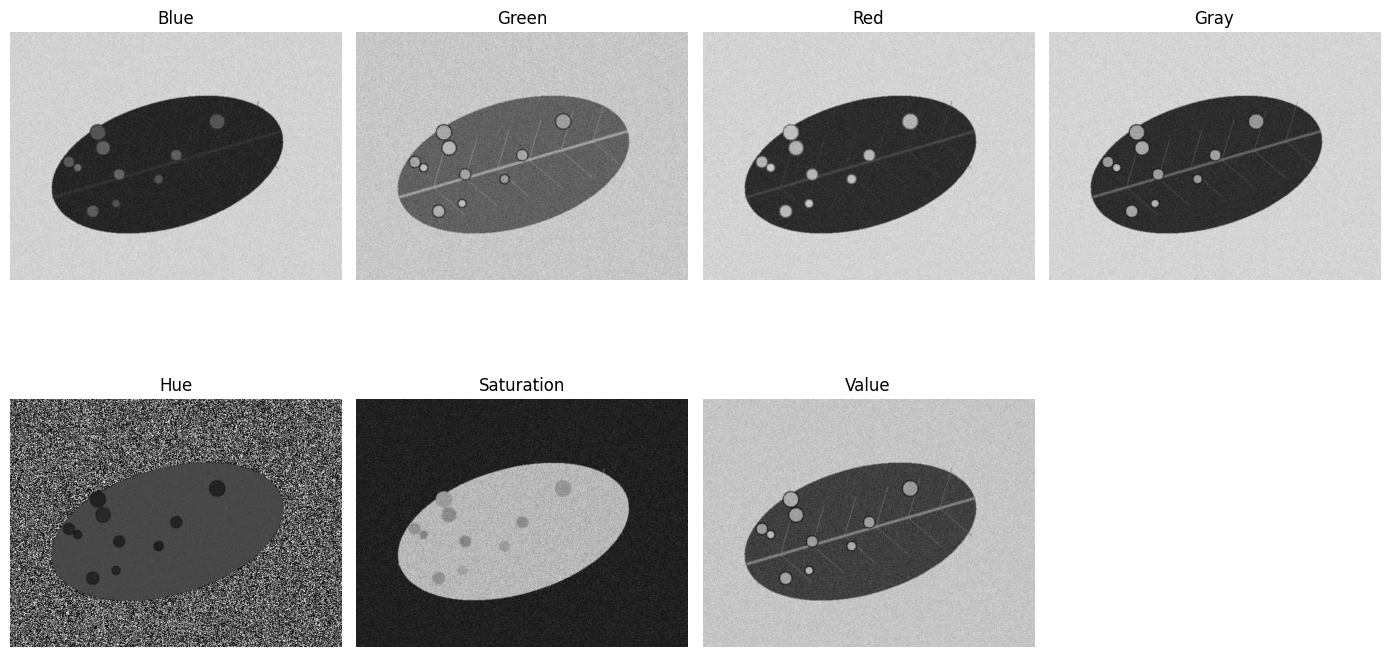

In [ ]:
B, G, R = cv2.split(img)

hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(hsv)

kanal = {
    "Blue": B,
    "Green": G,
    "Red": R,
    "Gray": gray,
    "Hue": H,
    "Saturation": S,
    "Value": V
}

plt.figure(figsize=(14, 8))

for i, (nama, data) in enumerate(kanal.items()):
    plt.subplot(2, 4, i + 1)
    plt.imshow(data, cmap="gray")
    plt.title(nama)
    plt.axis("off")

plt.tight_layout()
plt.show()

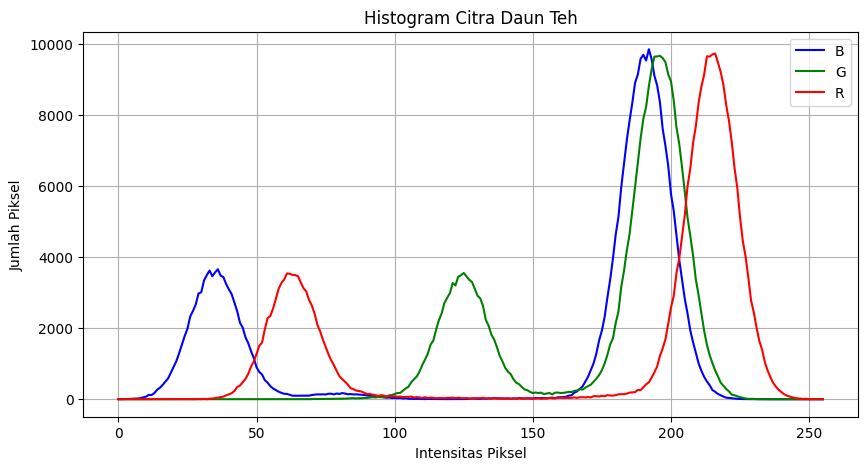

In [ ]:
warna = ("b", "g", "r")
plt.figure(figsize=(10, 5))

for i, col in enumerate(warna):
    hist = cv2.calcHist([img], [i], None, [256], [0, 256])
    plt.plot(hist, color=col, label=col.upper())

plt.title("Histogram Citra Daun Teh")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")
plt.legend()
plt.grid()
plt.show()

In [ ]:
hasil_statistik = []

for nama, data in kanal.items():
    hasil_statistik.append({
        "Kanal": nama,
        "Mean": np.mean(data),
        "Standar Deviasi": np.std(data),
        "Minimum": np.min(data),
        "Maksimum": np.max(data)
    })

df_statistik = pd.DataFrame(hasil_statistik)
display(df_statistik.round(2))

df_statistik.to_csv(
    os.path.join(HASIL, "b2_statistik_kanal.csv"),
    index=False
)

,Kanal,Mean,Standar Deviasi,Minimum,Maksimum
0,Blue,147.09,70.04,0,232
1,Green,176.39,32.78,57,235
2,Red,173.45,67.55,22,255
3,Gray,172.17,46.67,67,228
4,Hue,60.66,62.18,0,179
5,Saturation,74.70,68.97,0,255
6,Value,190.57,40.87,81,255


In [ ]:
def hitung_kb(kanal_citra, mask_daun, mask_bercak):
    daun = kanal_citra[mask_daun > 0]
    bercak = kanal_citra[mask_bercak > 0]

    if len(daun) == 0 or len(bercak) == 0:
        return np.nan

    std_daun = np.std(daun)

    if std_daun == 0:
        return np.nan

    return abs(np.mean(bercak) - np.mean(daun)) / std_daun


mask_daun = cv2.imread(
    os.path.join(MASK_DAUN, nama_file),
    cv2.IMREAD_GRAYSCALE
)

mask_bercak = cv2.imread(
    os.path.join(MASK_BERCAK, nama_file),
    cv2.IMREAD_GRAYSCALE
)

if mask_daun is None or mask_bercak is None:
    raise FileNotFoundError("Mask daun atau mask bercak tidak ditemukan.")

hasil_kb = []

for nama, data in kanal.items():
    nilai = hitung_kb(data, mask_daun, mask_bercak)
    hasil_kb.append({
        "Kanal": nama,
        "Kontras Bercak (KB)": nilai
    })

df_kb = pd.DataFrame(hasil_kb)
display(df_kb.round(4))

df_kb.to_csv(
    os.path.join(HASIL, "b2_kontras_bercak.csv"),
    index=False
)

,Kanal,Kontras Bercak (KB)
0,Blue,2.4369
1,Green,1.5122
2,Red,3.5839
3,Gray,2.8942
4,Hue,3.4224
5,Saturation,1.5196
6,Value,2.3266


In [ ]:
hasil_pengujian = []

for kelas, rentang in {
    "ringan": range(21, 41),
    "berat": range(41, 61)
}.items():

    for nomor in rentang:
        nama = f"teh_{nomor:03d}.png"

        img_uji = cv2.imread(os.path.join(CITRA, nama))
        md = cv2.imread(
            os.path.join(MASK_DAUN, nama),
            cv2.IMREAD_GRAYSCALE
        )
        mb = cv2.imread(
            os.path.join(MASK_BERCAK, nama),
            cv2.IMREAD_GRAYSCALE
        )

        if img_uji is None or md is None or mb is None:
            print("File dilewati:", nama)
            continue

        gray_uji = cv2.cvtColor(img_uji, cv2.COLOR_BGR2GRAY)
        hsv_uji = cv2.cvtColor(img_uji, cv2.COLOR_BGR2HSV)

        kanal_uji = {
            "Blue": img_uji[:, :, 0],
            "Green": img_uji[:, :, 1],
            "Red": img_uji[:, :, 2],
            "Gray": gray_uji,
            "Hue": hsv_uji[:, :, 0],
            "Saturation": hsv_uji[:, :, 1],
            "Value": hsv_uji[:, :, 2]
        }

        for nama_kanal, data in kanal_uji.items():
            hasil_pengujian.append({
                "Kelas": kelas,
                "Nama Citra": nama,
                "Kanal": nama_kanal,
                "KB": hitung_kb(data, md, mb)
            })

df_pengujian = pd.DataFrame(hasil_pengujian)

display(df_pengujian.head(10))

df_pengujian.to_csv(
    os.path.join(HASIL, "b2_pengujian_kanal.csv"),
    index=False
)

print("Jumlah citra yang berhasil diuji:",
      df_pengujian["Nama Citra"].nunique())

,Kelas,Nama Citra,Kanal,KB
0,ringan,teh_021.png,Blue,1.557957
1,ringan,teh_021.png,Green,0.776689
2,ringan,teh_021.png,Red,5.775046
3,ringan,teh_021.png,Gray,3.317178
4,ringan,teh_021.png,Hue,4.591980
5,ringan,teh_021.png,Saturation,0.615491
6,ringan,teh_021.png,Value,2.245631
7,ringan,teh_022.png,Blue,0.713433
8,ringan,teh_022.png,Green,0.046681
9,ringan,teh_022.png,Red,5.963428


Jumlah citra yang berhasil diuji: 40


,Kelas,Kanal,KB
0,berat,Blue,1.3313
1,berat,Gray,2.1426
2,berat,Green,0.6312
3,berat,Hue,2.8662
4,berat,Red,3.2458
5,berat,Saturation,0.8506
6,berat,Value,1.5018
7,ringan,Blue,1.2355
8,ringan,Gray,2.2572
9,ringan,Green,0.3788


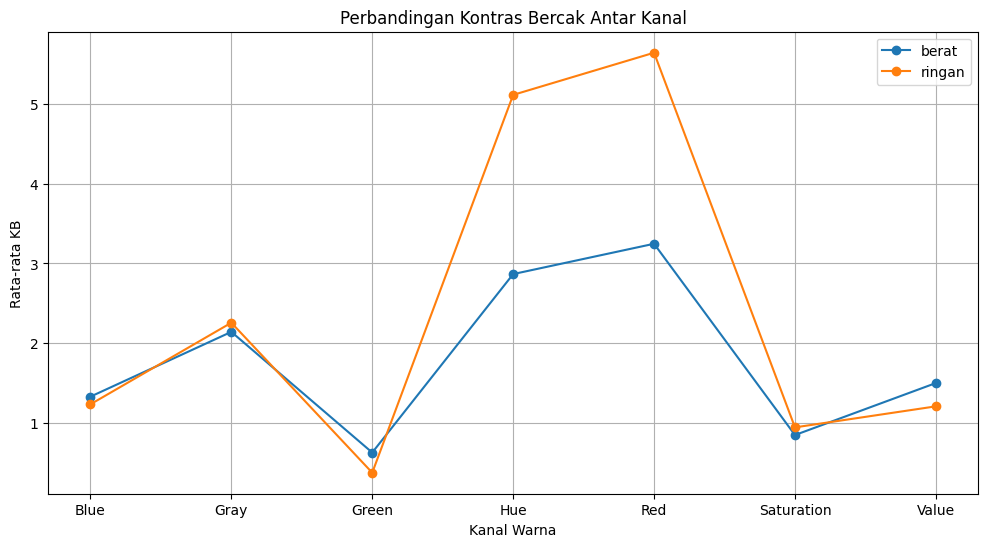

In [ ]:
ringkasan = (
    df_pengujian
    .groupby(["Kelas", "Kanal"])["KB"]
    .mean()
    .reset_index()
)

display(ringkasan.round(4))

plt.figure(figsize=(12, 6))

for kelas in ringkasan["Kelas"].unique():
    data_kelas = ringkasan[ringkasan["Kelas"] == kelas]
    plt.plot(
        data_kelas["Kanal"],
        data_kelas["KB"],
        marker="o",
        label=kelas
    )

plt.title("Perbandingan Kontras Bercak Antar Kanal")
plt.xlabel("Kanal Warna")
plt.ylabel("Rata-rata KB")
plt.legend()
plt.grid()
plt.show()

ringkasan.to_csv(
    os.path.join(HASIL, "b2_ringkasan_kontras.csv"),
    index=False
)

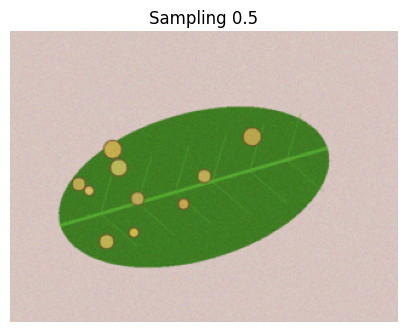

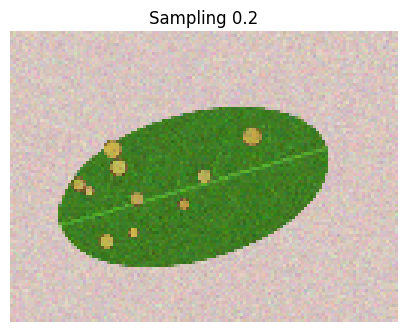

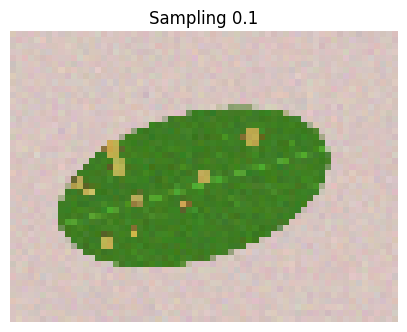

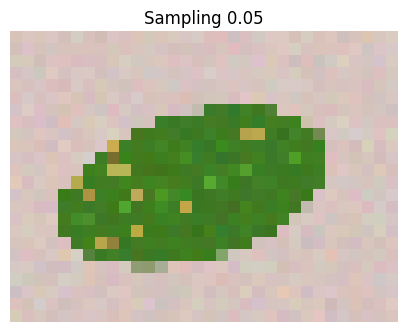

,Faktor Sampling,Lebar,Tinggi,Jumlah Piksel
0,0.50,320,240,76800
1,0.20,128,96,12288
2,0.10,64,48,3072
3,0.05,32,24,768


In [ ]:
faktor_sampling = [0.5, 0.2, 0.1, 0.05]
hasil_sampling = []

for faktor in faktor_sampling:
    ukuran = (
        max(1, int(img.shape[1] * faktor)),
        max(1, int(img.shape[0] * faktor))
    )

    citra_sampling = cv2.resize(img, ukuran)

    hasil_sampling.append({
        "Faktor Sampling": faktor,
        "Lebar": citra_sampling.shape[1],
        "Tinggi": citra_sampling.shape[0],
        "Jumlah Piksel": citra_sampling.shape[0] * citra_sampling.shape[1]
    })

    plt.figure(figsize=(5, 4))
    plt.imshow(cv2.cvtColor(citra_sampling, cv2.COLOR_BGR2RGB))
    plt.title(f"Sampling {faktor}")
    plt.axis("off")
    plt.show()

df_sampling = pd.DataFrame(hasil_sampling)
display(df_sampling)

df_sampling.to_csv(
    os.path.join(HASIL, "b2_sampling.csv"),
    index=False
)

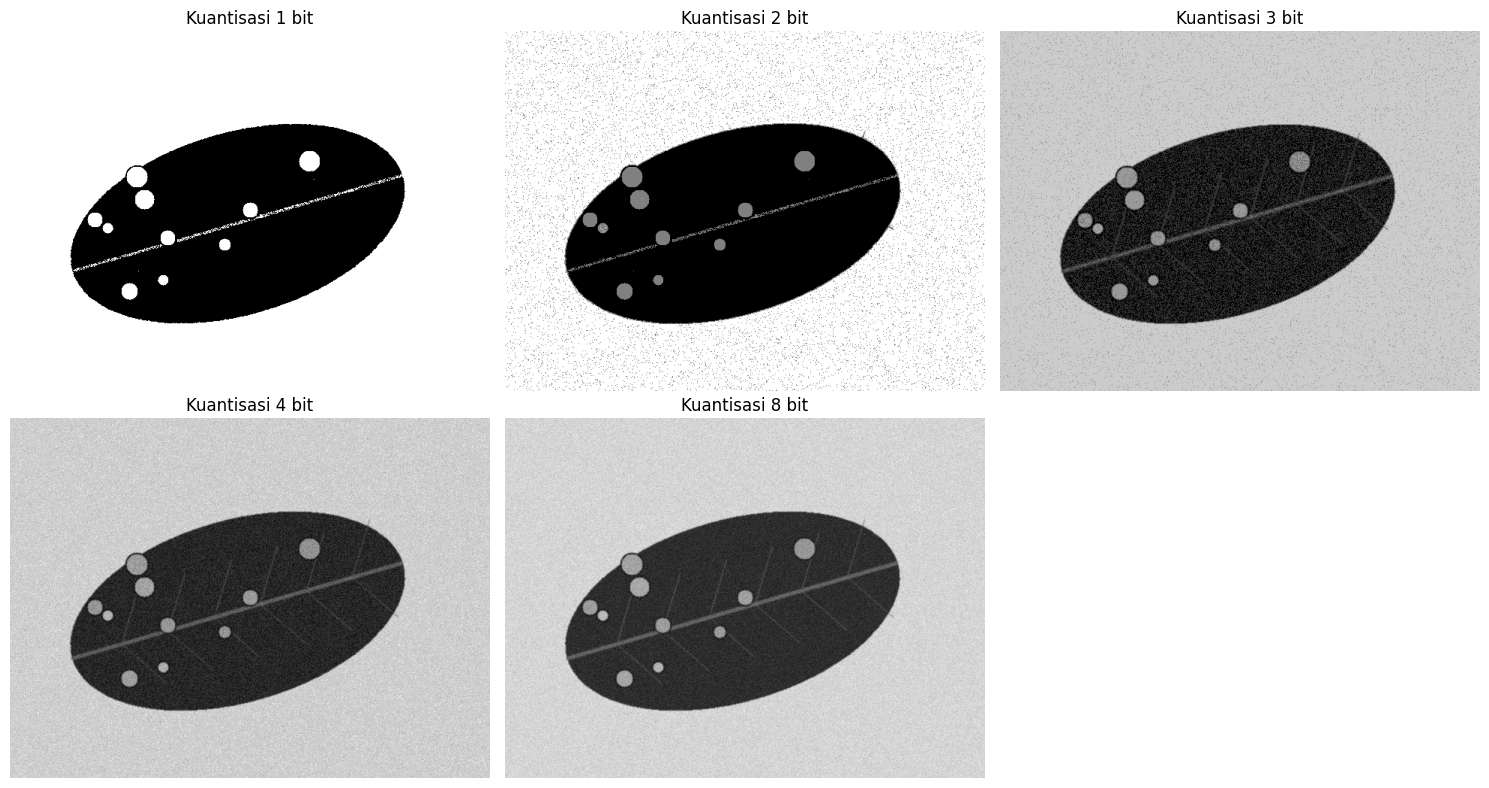

,Bit,Jumlah Level
0,1,2
1,2,4
2,3,8
3,4,16
4,8,256


In [ ]:
bit_list = [1, 2, 3, 4, 8]
hasil_kuantisasi = []

gray_float = gray.astype(np.float32)

plt.figure(figsize=(15, 8))

for i, bit in enumerate(bit_list):
    level = 2 ** bit
    langkah = 256 / level

    citra_q = (
        np.floor(gray_float / langkah) * langkah
    ).clip(0, 255).astype(np.uint8)

    hasil_kuantisasi.append({
        "Bit": bit,
        "Jumlah Level": level
    })

    plt.subplot(2, 3, i + 1)
    plt.imshow(citra_q, cmap="gray")
    plt.title(f"Kuantisasi {bit} bit")
    plt.axis("off")

plt.tight_layout()
plt.show()

df_kuantisasi = pd.DataFrame(hasil_kuantisasi)
display(df_kuantisasi)

df_kuantisasi.to_csv(
    os.path.join(HASIL, "b2_kuantisasi.csv"),
    index=False
)

In [ ]:
print("PENGERJAAN B2 SELESAI")
print("=" * 40)

print("Lokasi hasil:", HASIL)
print("\nFile hasil yang tersimpan:")

for file in sorted(os.listdir(HASIL)):
    print("-", file)

PENGERJAAN B2 SELESAI
Lokasi hasil: /content/drive/MyDrive/simuteh-1004/hasil

File hasil yang tersimpan:
- b1_bgr_rgb.png
- b1_citra_daun.png
- b2_kontras_bercak.csv
- b2_kuantisasi.csv
- b2_pengujian_kanal.csv
- b2_ringkasan_kontras.csv
- b2_sampling.csv
- b2_statistik_kanal.csv
